In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [ ]:
df = pd.read_csv("Student.csv")

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [ ]:
df.shape
df.info()
df.describe()
df.isnull().sum()
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


np.int64(0)

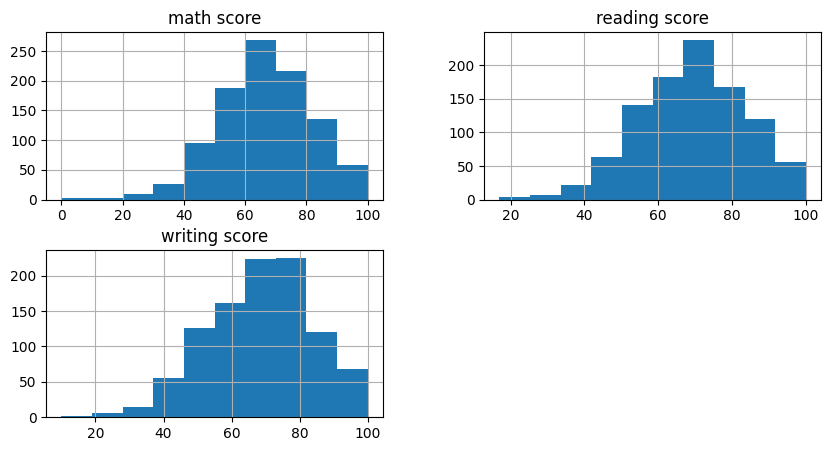

In [ ]:
df[['math score',
    'reading score',
    'writing score']].hist(figsize=(10, 5))

plt.show()

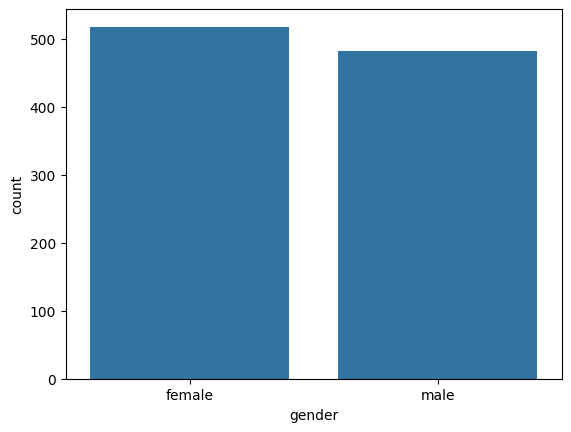

In [ ]:
sns.countplot(data=df, x='gender')
plt.show()

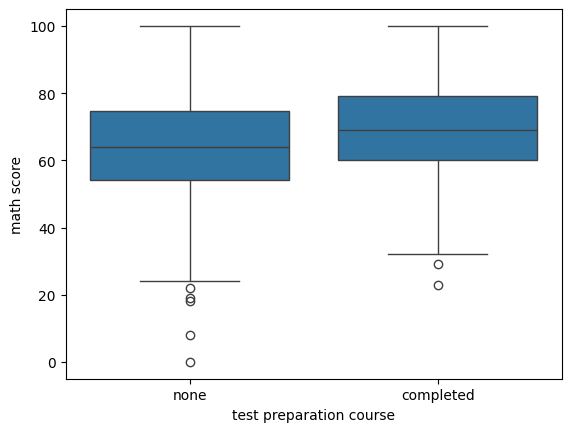

In [ ]:
sns.boxplot(
    data=df,
    x='test preparation course',
    y='math score'
)

plt.show()

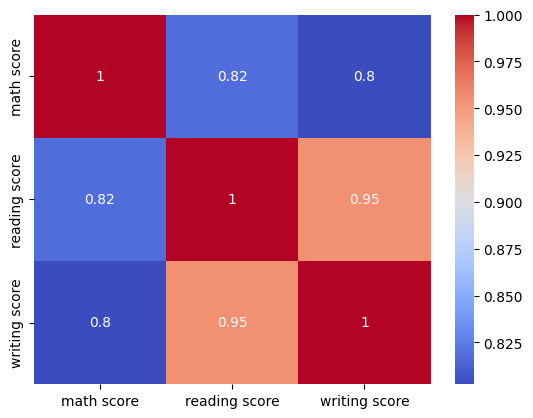

In [ ]:
sns.heatmap(
    df[['math score',
        'reading score',
        'writing score']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.show()

In [ ]:
df['average_score'] = (
    df['math score'] +
    df['reading score'] +
    df['writing score']
) / 3

In [ ]:
X = df.drop(columns=[
    'math score',
    'reading score',
    'writing score',
    'average_score'
])

y = df['average_score']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
categorical_features = X.select_dtypes(
    include='object'
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

In [ ]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_features),

    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ), categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [ ]:
model = keras.Sequential([
    layers.Input(
        shape=(X_train_processed.shape[1],)
    ),

    layers.Dense(64, activation='relu'),

    layers.Dense(32, activation='relu'),

    layers.Dense(1, activation='linear')
])

In [ ]:
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [ ]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_processed,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 4748.8945 - mae: 67.4446 - val_loss: 4591.4067 - val_mae: 66.2608
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 4513.1260 - mae: 65.6680 - val_loss: 4274.4658 - val_mae: 63.8167
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 4056.6204 - mae: 62.0675 - val_loss: 3636.2896 - val_mae: 58.5886
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 3218.3311 - mae: 54.8436 - val_loss: 2591.1816 - val_mae: 48.8330
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 2025.5247 - mae: 42.4762 - val_loss: 1330.1986 - val_mae: 33.7158
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 865.9074 - mae: 25.5918 - val_loss: 421.5301 - val_mae: 17.3080
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 276.0771 - mae: 13.4947 - val_loss: 211.2782 - val_mae: 11.2353
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 200.0728 - mae: 11.4475 - val_loss: 206.0085 - val_mae: 11.0280
Epo

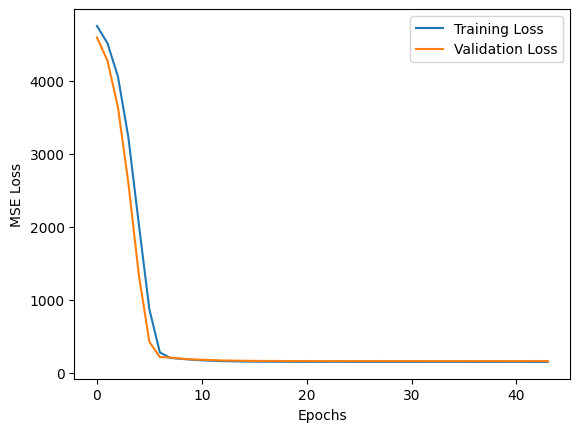

In [ ]:
plt.plot(history.history['loss'],
         label='Training Loss')

plt.plot(history.history['val_loss'],
         label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.legend()
plt.show()

In [ ]:
y_pred = model.predict(X_test_processed).flatten()

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


In [ ]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 10.370811042785645
MSE: 175.53473206148414
RMSE: 13.248952111826963
R2 Score: 0.18114687942716756


In [ ]:
import os

os.makedirs("models", exist_ok=True)

In [ ]:
model.save("models/ann_model.keras")

In [ ]:
import joblib

joblib.dump(
    preprocessor,
    "models/preprocessor.pkl"
)

['models/preprocessor.pkl']

In [ ]:
from pathlib import Path
import joblib

project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

model_dir = project_dir / "models"
model_dir.mkdir(exist_ok=True)

# Save fresh ANN
model.save(model_dir / "ann_model.keras")

# Save fitted preprocessing pipeline
joblib.dump(
    preprocessor,
    model_dir / "preprocessor.pkl"
)

print("ANN model and preprocessor saved successfully!")